In this notebook, I code linear regression through gradient descent from scratch. This code is based on my notes and documentation on the math for the derivations of gradent descent. The formulas are included in this notebook, but a more detailed version of the notes and derivations can be found in Github.

In [56]:
import numpy as np
import matplotlib.pyplot as plt
np.random.seed(42) #Making sure a fixed order of numbers is generated

In [57]:
class LinearRegressionGd:
    def __init__(self, lr=0.01, epochs=1000): #Initializing learning rate and epochs
        self.lr = lr
        self.epochs = epochs
        self.m = 0
        self.b = 0
        self.loss_history = []
        
    def predict(self, X):
        return (self.m * X) + self.b #Returning the predicted values
        
        
    
    def fit(self, X, y):
        n = len(X) #Getting the number of data points
        for i in range(self.epochs):
            y_pred = self.predict(X)
            residuals = y - y_pred #Getting residual values
            self.loss_history.append(np.mean(residuals ** 2)) #MSE: mean of the squared residuals
            dm = -2 * np.mean(residuals * X) #Using the derived partial derivative dm to see how much m changes
            db = -2 * (np.mean(residuals)) #Using derived partial derivative db to see how much b changes
            self.m -= self.lr * dm #updating the two
            self.b -= self.lr * db
            
        return self
            
            
    

In [68]:

x = np.random.rand(100) * 10 #m will be a random float between 0 and 100
y = 3*x + 7 + np.random.normal(0, 1, 100)

model = LinearRegressionGd()
model.fit(x, y)
print(model.m, model.b)

3.053545907634249 6.719198198999012


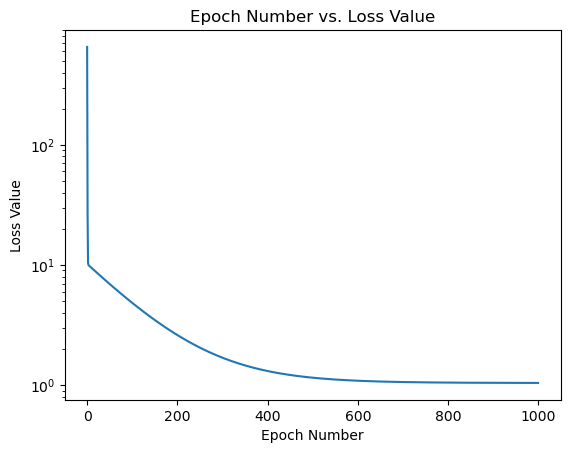

In [61]:
#Graphing the epoch number vs loss value

plt.plot(model.loss_history)
plt.xlabel('Epoch Number')
plt.ylabel('Loss Value')
plt.title('Epoch Number vs. Loss Value')
plt.yscale('log')
plt.show()

In [62]:
#Printing loss history array
print(model.loss_history[:10])
print(model.loss_history[-5:])

[653.3062416002903, 26.173999257449676, 10.440750053308298, 9.970818695364644, 9.882591364627977, 9.80456555091709, 9.727461348431374, 9.651041232141944, 9.575293457713004, 9.500211968223631]
[1.0408691148951872, 1.0408568563978733, 1.0408447057269254, 1.0408326619338972, 1.040820724078686]


From the graph, we can see that the loss started around 470, and collapses to around 10 within 20 epochs. Therefore, the model minimizes quickly the first few epochs, but then it is a long way to around 1. The final MSE is around 1, because of the random noise added in

PREDICTIONS FOR CHANGING LEARNING RATE: (epochs stay constant at 1000)

- 1e-5: 1, 4.5
- 1e-3: 2.5, 5.0
- 0.01: 2.99, 5.99
- 0.1: 3.4, 6.5
- 0.5: 4, 8

ACTUAL LEARNING RATE RESULTS:

- 1e-5: 1.95, 0.3 (MSE ended at ~ 150)
- 1e-3: 3.6, 2.8 (MSE ended at ~ 4.5)
- 0.01: 3, 6.95 (MSE ended at ~0.88)
- 0.1: GETTING AN ERROR (nan nan)
- 0.5: GETTING AN ERROR (nan nan)

At Lr = 0.1 and 0.5, the learning rate overshoots the curvature of the loss bowl, and it keeps on going in a cycle of overshooting unitl it gets to infinity, hence the nan error.

The bowl. Picture a 3D surface: the floor is every possible (m, b) pair, and the height at each point is the loss for those values. For linear regression that surface is a smooth bowl — one lowest point, which is the optimal (m, b). Your model starts at (0, 0), somewhere up on the rim, and gradient descent is the process of walking down to the bottom.

The gradient tells you the steepness and direction at wherever you’re currently standing. Steep wall → big gradient → big step. Near the bottom → shallow → small step. That’s why your loss curve dropped 83% on epoch one and barely moved by epoch 900.

Convergence = the walk reaches the bottom and stays there. Your loss settles at 0.977 and stops changing. That’s what lr=0.01 did.

Divergence = the walk escapes the bowl entirely. Here’s the mechanism at lr=0.1: you’re on the wall, the gradient says “downhill is that way, and it’s steep.” You take a step of size lr × gradient — but the step is so long you fly past the bottom and land on the opposite wall, higher than where you started. Now the gradient there is even bigger, so your next step is even longer, landing higher still. Each iteration throws you further out. Within ~20 epochs the numbers exceed what a float can hold → inf → nan.

The analogy: rolling a ball down a valley versus firing it. Too much force and it doesn’t settle at the bottom — it shoots up the far side, comes back harder, and eventually leaves the valley altogether.

Why lr controls this: the gradient gives direction and steepness but says nothing about how far away the bottom is. lr is your guess at step length. Too short → you crawl (1e-5). Too long → you escape (0.1). The safe range depends on how curved the bowl is, which is why it’s problem-specific and why you had to find it experimentally.


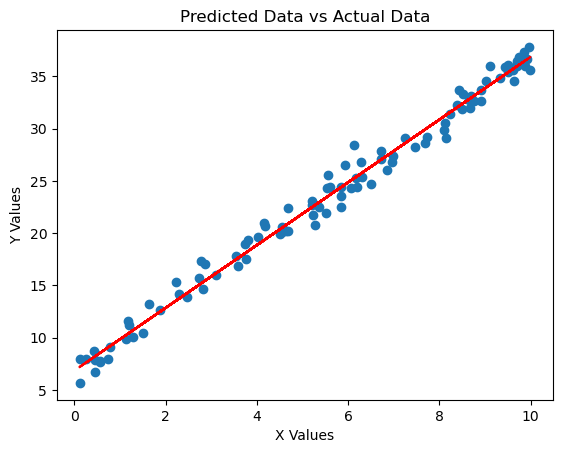

In [63]:
#Plotting the synthetic data vs the predicted data
plt.scatter(x, y)
plt.plot(x, model.predict(x), color='red')
plt.xlabel("X Values")
plt.ylabel("Y Values")
plt.title("Predicted Data vs Actual Data")
plt.show()


/var/folders/9h/954tl1g160x3skhwsr60d5fc0000gn/T/ipykernel_85453/3248616358.py:19: RuntimeWarning: overflow encountered in square
  self.loss_history.append(np.mean(residuals ** 2)) #MSE: mean of the squared residuals
/var/folders/9h/954tl1g160x3skhwsr60d5fc0000gn/T/ipykernel_85453/3248616358.py:22: RuntimeWarning: invalid value encountered in scalar subtract
  self.m -= self.lr * dm #updating the two
/var/folders/9h/954tl1g160x3skhwsr60d5fc0000gn/T/ipykernel_85453/3248616358.py:23: RuntimeWarning: invalid value encountered in scalar subtract
  self.b -= self.lr * db


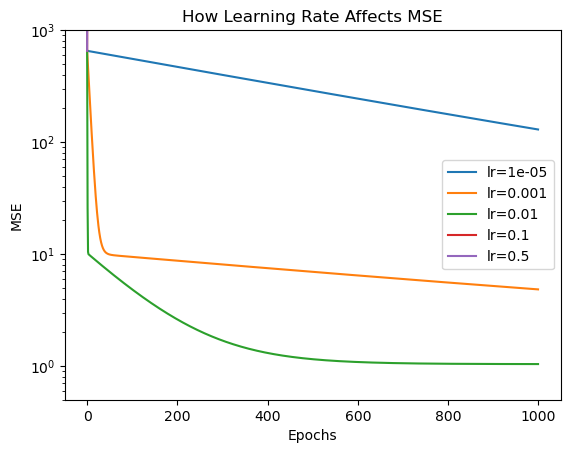

In [64]:
rates = [1e-5, 1e-3, 0.01, 0.1, 0.5]
models = {}
for lr in rates:
    m = LinearRegressionGd(lr, epochs=1000)
    m.fit(x, y)
    models[lr] = m
    plt.plot(models[lr].loss_history, label=f'lr={lr}')
    
plt.ylim(0.5, 1000)
plt.yscale('log')
plt.xlabel('Epochs')
plt.ylabel('MSE')
plt.title('How Learning Rate Affects MSE')
plt.legend()
plt.show()
    


- Blue (1e-5): barely descends after 1,000 epochs — far too slow
- Orange (1e-3): drops fast, then crawls — still unconverged at 1,000
- Green (0.01): clean descent to the noise floor at 1.0 — correct
- Red/purple: instant explosion
- NOTE: Red and Purple are visible, but the overshoot is so significant that the numbers overflow